# Coding Project 2: Credit Analytics

**Names of all group members:**

Giulio Tonielli, Isabella Ceotto, Zhenbin Marco Fu, Ariba Mbeche

---

All code below is only suggestive and you may as well use different approaches.
Make sure that all requested quantities are printed or shown in tables/plots in the executed notebook.
A concise *Project Report* is required at the end of the notebook (see the last cells).

In [40]:
# Exercise 1.
import numpy as np
np.random.seed(0)  # for reproducibility

# simulate explanatory variables x (the age and monthly income are assumed here to follow a continuous uniform distribution)
m, n = 20_000, 10_000
num_samples = m + n

# Columns: age, monthly income (in CHF 1000), self-employed indicator
x = np.column_stack([
    np.random.uniform(18, 80, size=num_samples),
    np.random.uniform(1, 15, size=num_samples),
    np.random.binomial(1, 0.10, size=num_samples),
])

# a) calculate and print the empirical means and standard deviations over the training data (i = 1, ..., m)

# Training data: observations 1 through m
x_train = x[:m]

feature_names = [
    "Age (years)",
    "Monthly income (CHF 1000)",
    "Self-employed indicator",
]

for j, name in enumerate(feature_names):
    print(
        f"{name}: mean = {x_train[:, j].mean():.4f}, "
        f"standard deviation = {x_train[:, j].std(ddof=0):.4f}"
    )

# b) Can you come up with a few (2 or 3) additional features that may be relevant?
# (you don't have to implement those of course, just write down your answer in text)


Age (years): mean = 48.7427, standard deviation = 18.0074
Monthly income (CHF 1000): mean = 7.9865, standard deviation = 4.0308
Self-employed indicator: mean = 0.1017, standard deviation = 0.3023


### Exercise 1.b
Some additional features that could be relevant are:
- current/existing debt
- debt to income ratio
- history of employment (job stability)
- credit history (including past missed payments)
- what industry or occupation

In [41]:
# Exercise 2.
# Building the datasets:
sigmoid = lambda x: 1. / (1. + np.exp(-x))

# build the first dataset
def p1(x):
    return sigmoid(13.3 - 0.33 * x[:, 0] + 3.5 * x[:, 1] - 3 * x[:, 2])


# build the second dataset
def p2(x):
    age_out = ((x[:, 0] < 25) | (x[:, 0] > 75)).astype(float)
    return sigmoid(5 - 10 * age_out + 1.1 * x[:, 1] - x[:, 2])

xi = np.random.uniform(0, 1, size=num_samples)
y1 = (xi <= p1(x)).astype(int)
y2 = (xi <= p2(x)).astype(int)

x_test = x[m:] #We divide our dataset into training and test sets, 
#where the first m samples are used for training and the remaining n samples are used for testing.
datasets = {1: y1, 2: y2}
for s, y in datasets.items():
    print(f"Dataset {s}: share of good payers: train = {y[:m].mean():.4f}, test = {y[m:].mean():.4f}")

Dataset 1: share of good payers: train = 0.9515, test = 0.9523
Dataset 2: share of good payers: train = 0.9482, test = 0.9513


### Exercise 2

We defined the sigmoid function and the two repayment probabilities. In $p_1$ the log-odds are linear in the features. In $p_2$ the probability drops sharply for applicants younger than 25 or older than 75, which is a non-linear effect of age. We then drew $\xi_i \sim U(0,1)$ and set $y_i = 1$ if $\xi_i \le p(x_i)$, so that each borrower repays with probability $p(x_i)$. The same $\xi_i$ are used for both datasets, so the only difference between them is the true model. In both datasets about 95% of borrowers are good payers, so the classes are quite unbalanced.

In [42]:
# Exercise 2. a)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
# "model = LogisticRegression().fit(X_data, Y_data)" fits a model
# "pred_X = model.predict_proba(X)" evaluates the model
# (note that it outputs both P(Y=0|X) and P(Y=1|X))
# "log_loss(Y, pred_X)" evaluates the negative conditional log likelihood (also called cross-entropy loss)

# Fit the models on both datasets

# Calculate and print the cross-entropy loss on both datasets for train and test
def cross_entropy(model, X, y) : 
    return log_loss(y, model.predict_proba(X))

logistic_models = {}
for s, y in datasets.items():
    logistic_models[s] = LogisticRegression(max_iter=1000).fit(x_train, y[:m])
    print(
        f"Dataset {s} Logistic regression: "
        f"cross-entropy loss on training data = {cross_entropy(logistic_models[s], x_train, y[:m]):.4f}, "
        f"cross-entropy loss on test data = {cross_entropy(logistic_models[s], x_test, y[m:]):.4f}"
    )


Dataset 1 Logistic regression: cross-entropy loss on training data = 0.0297, cross-entropy loss on test data = 0.0349
Dataset 2 Logistic regression: cross-entropy loss on training data = 0.1535, cross-entropy loss on test data = 0.1486


### Exercise 2.a

We wrote a small helper function that computes the cross-entropy loss from the predicted probabilities, and we fitted a logistic regression on the training data of each dataset. On dataset 1 the loss is low, since the true model $p_1$ has exactly the logistic form. On dataset 2 the loss is several times higher, because a model that is linear in age cannot capture the "too young or too old" effect in $p_2$. In both cases train and test losses are close, so the model does not overfit.

In [43]:
# Exercise 2. b)
# Calculate normalized data
# (as in the assignment: divide by the empirical standard deviations of the TRAINING data,
#  for both training and test data)
sigma_hat = x_train.std(axis=0, ddof=0)
x_tilde = x / sigma_hat
xt_train, xt_test = x_tilde[:m], x_tilde[m:]


In [44]:
# Exercise 2.b) (i) and (ii)
from sklearn.svm import SVC
# "model = SVC(kernel='rbf', gamma=GAMMA, C=C, probability=True)" creates
# a model with kernel exp(-GAMMA \|x-x'\|_2^2) and regularization parameter C (note the relation between C and the parameter lambda from the lecture).
# "probability=True" enables the option "model.predict_proba(X)" to predict probabilities from the regression function \hat{f}^{svm}.
# "model.fit(X, Y)" optimizes the model parameters (using hinge loss)

# Fit the models for both datasets (this can take up to 60 seconds with SVC)
# Note: "model.fit(...)" modifies the model object in place, so use a separate model object
# for each dataset if you want to keep both fitted models.
svm_models = {}
for s, y in datasets.items():
    svm_models[s] = SVC(kernel='rbf', gamma=0.1, C=0.2, probability=True, random_state=42).fit(xt_train, y[:m])



c:\Users\tonie\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\tonie\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


### Exercise 2.b (i)–(ii)

First, we compute the empirical standard deviation $\hat{\sigma}_j$ of each feature on the training data ($i = 1, \dots, m$). We then normalize both training and test data as $\tilde{x}_{ij} = x_{ij}/\hat{\sigma}_j$, as required by the exercise. We use only the training $\hat{\sigma}_j$, so no information from the test set is used. Note that this is a normalization, not a standardization: the mean is not subtracted.

- `SVC(kernel='rbf', gamma=0.1, C=0.2)` fits the SVM on the normalized training data, with kernel $k(x,x') = \exp(-\tfrac{1}{10}\|x-x'\|_2^2)$ and $C = 1/(2\lambda m) = 0.2$.
- `probability=True` adds Platt scaling: a logistic function is fitted on the SVM scores (via 5-fold cross-validation), so `predict_proba` returns repayment probabilities. `random_state=42` makes it reproducible.

**Note on the `FutureWarning`:** scikit-learn ≥ 1.9 marks `probability=True` as deprecated. It still works and performs Platt scaling as required. We kept it because the assignment suggests it; the equivalent new form is `CalibratedClassifierCV(SVC(...), method="sigmoid", ensemble=False)`. 

In [45]:
# Exercise 2.b (iii)
# "model.predict_proba(X)" predicts probabilities from features (note that it outputs both P(Y=0|X) and P(Y=1|X))

# Calculate and print the cross-entropy loss on both normalized datasets for train and test
for s, y in datasets.items():
    print(f"Dataset {s} - SVM (Platt): cross-entropy train = {cross_entropy(svm_models[s], xt_train, y[:m]):.4f}, "
          f"cross-entropy test = {cross_entropy(svm_models[s], xt_test, y[m:]):.4f}")

Dataset 1 - SVM (Platt): cross-entropy train = 0.0319, cross-entropy test = 0.0387
Dataset 2 - SVM (Platt): cross-entropy train = 0.0712, cross-entropy test = 0.0672


### Exercise 2.b (iii)

On dataset 1 both models perform similarly, since the log-odds of $p_1$ are linear in the features, which suits logistic regression. On dataset 2 the SVM is clearly better: the age effect in $p_2$ (below 25 or above 75) is non-linear, and the RBF kernel captures it while logistic regression cannot. Train and test losses are close, so there is no overfitting.

In [46]:
# Exercise 2.b (iv)
#Would the results change using standardized data instead of normalized data? No need to run any code here, only explain your reasoning.



### Exercise 2.b (iv)

No, the results would not change if we use the standardized data instead of the normalized data.

The SVM only "sees" the data through the kernel $k(x,x') = \exp(-\tfrac{1}{10}\|x-x'\|^2)$, which depends only on the difference $x - x'$. Standardizing instead of normalizing means subtracting the constant $\hat{\mu}_j/\hat{\sigma}_j$ from every observation, and this cancels out in the difference:

$$\tilde{z}_i - \tilde{z}_{i'} = \tilde{x}_i - \tilde{x}_{i'}$$

So the distances between points are the same, the kernel matrix is the same, and the SVM gives exactly the same scores $\hat{f}^{svm}_s$. Since Platt scaling is fitted on these scores, the predicted probabilities and the cross-entropy losses would also be the same.

The division by $\hat{\sigma}_j$ is what actually matters, because it puts the features on comparable scales. Without it, age (std ≈ 18) would dominate the distance compared to the self-employed dummy (std ≈ 0.3). The mean subtraction is just a shift, and the RBF kernel is not affected by shifts.

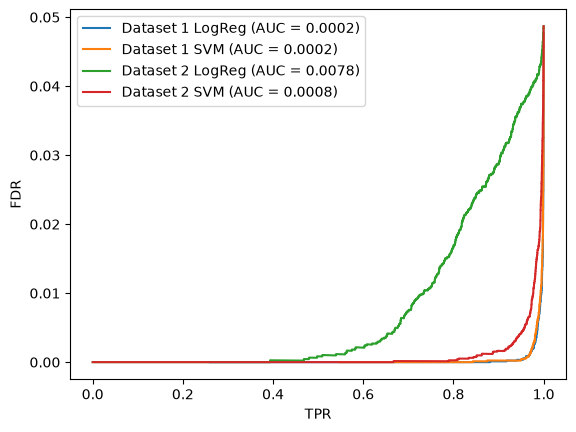

AUC of Dataset 1 (Logistic Regression): 0.0002
AUC of Dataset 1 (SVM): 0.0002
AUC of Dataset 2 (Logistic Regression): 0.0078
AUC of Dataset 2 (SVM): 0.0008


In [47]:
# Exercise 2.c
# Plot the FDR/TPR-curves with the TPR on the horizontal axis and the FDR on the vertical axis,
# and compute the AUC of each plotted curve on the test data.
import matplotlib.pyplot as plt
# Thresholds c: you may use all distinct predicted probabilities (this gives the exact curve), or a grid of
# values in [0, 1]. A uniform grid such as np.linspace(0, 1, 100) can be too coarse when many predicted
# probabilities are very close to 1. Check that your curve covers TPR values from (close to) 0 to 1.

# To approximately calculate the AUC, it is fine to simply use Riemann sums.
# This means, if you have N (a_i, b_i) pairs for the curves, ordered such that a_1 <= a_2 <= ... <= a_N,
# then you may simply use the sum
# sum_{i=1}^{N-1} (b_i + b_{i+1})/2 * (a_{i+1}-a_i)
# as the approximation of the integral (or AUC)


# first data set & logistic regression:
# (the code should be reusable for all cases, only exchanging datasets and predicted probabilities depending on the model)

def FDRTPRAUC(y,pred_proba):
      #reorder the elements from the smallest to the biggest
    thresholds = np.unique(pred_proba)[::-1]
    # Calculate positives (only depending on the dataset)
    P=np.sum(y==1)

    TPR_list = []
    FDR_list = []
    for th in thresholds:
        pred_positives = (pred_proba >= th)
        # Calculate true positives for all threshold values
        TP = np.sum(pred_positives & (y == 1))
        # Calculate false positives for all threshold values
        FP = np.sum(pred_positives & (y == 0))
        # Calculate FDR and TPR rate (points on the FDR/TPR curve) and the AUC
        FDR=FP/(FP+TP)
        TPR=TP/P
        TPR_list.append(TPR)
        FDR_list.append(FDR)
        
    TPR_array = np.array(TPR_list)
    FDR_array = np.array(FDR_list)
    #Computation for AUC    
    AUC=0
    for i in range(len(TPR_array) - 1):
        AUC+=(FDR_array[i]+FDR_array[i+1])/2*(TPR_array[i+1]-TPR_array[i])        
    return TPR_array, FDR_array, AUC
# second data set & logistic regression:
auc_results = {}
for s, y in datasets.items():
    y_test = y[m:]
    pred_proba = logistic_models[s].predict_proba(x_test)[:, 1]
    TPR_array, FDR_array, AUC=FDRTPRAUC(y_test, pred_proba)
    auc_results[f"Dataset {s} (Logistic Regression)"] = AUC
    plt.plot(TPR_array,FDR_array, label=f'Dataset {s} LogReg (AUC = {AUC:.4f})')
    plt.xlabel('TPR')
    plt.ylabel('FDR')
# first data set and SVM:
# second data set and SVM:
    svm_pred_proba = svm_models[s].predict_proba(xt_test)[:, 1]
    TPR_svm, FDR_svm, AUC_svm = FDRTPRAUC(y_test, svm_pred_proba)
    auc_results[f"Dataset {s} (SVM)"] = AUC_svm
    plt.plot(TPR_svm,FDR_svm, label=f'Dataset {s} SVM (AUC = {AUC_svm:.4f})')
    plt.xlabel('TPR')
    plt.ylabel('FDR')

plt.legend()
plt.show()


# Print the AUC values.
for model_name, auc_val in auc_results.items():
    print(f"AUC of {model_name}: {auc_val:.4f}")
# Briefly explain (in a Markdown cell or comments) how you construct the curves, interpret what
# the AUC means in this setting, and compare the two models on both data sets.

2.C) The curve is constructed by using threshold given by the distinct predicted probability. FDR is plotted vertically and TPR horizontally.

AUC is the sum of the "errors" for prediction: FDR is plotted in vertical, hence AUC simply means the sum of these vertical lines. For every horizontal point, lower a curve is, the better is the result, since one wants to reduce FDR with respect to TPR. Hence smaller the AUC is, better is the result.

In this case, SVM model fits better since the AUC of SVM on the test set of both data sets are not higher than the one of logistic regression.  

Loans accepted in strategy i:  10000
The expected profit for strategy i is:  22356.6888
The 95%-VaR for strategy i is:  -2455.0  CHF

Loans accepted in strategy ii:  6992
The expected profit for strategy ii is:  4857.6584
The 95%-VaR for strategy ii is:  6840.0  CHF

Loans accepted in strategy iii:  8841
The expected profit for strategy iii is:  61962.0794
The 95%-VaR for strategy iii is:  -54070.0  CHF



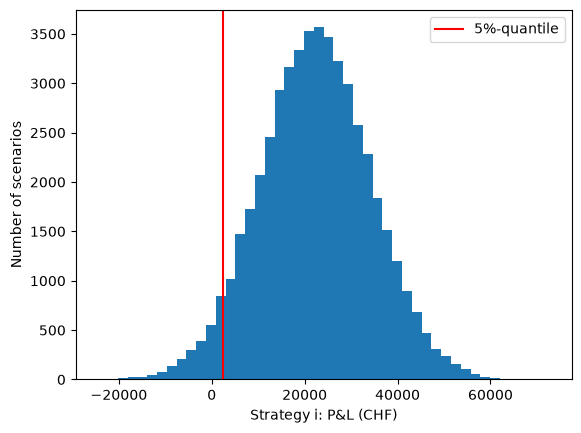

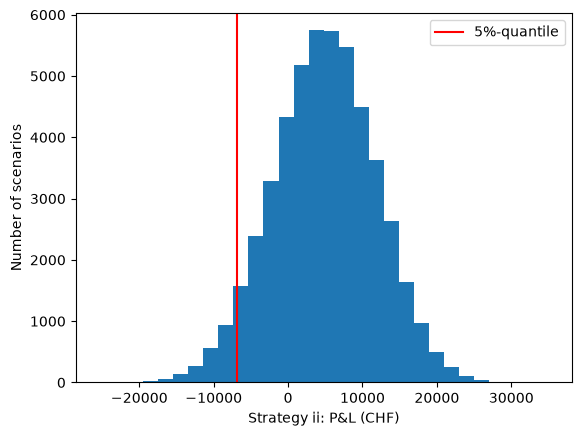

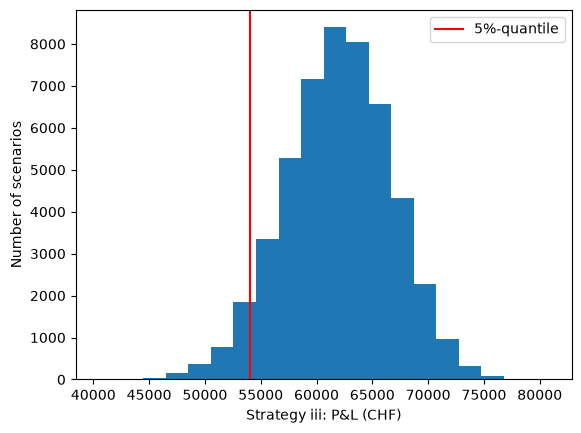

In [48]:
# Exercise 3.

# Define matrix D.
# D is of size n x 50_000, where 50_000 is the number of market scenarios
NUM_SIMULATIONS = 50_000
rng = np.random.default_rng(seed=42)   # own generator for the market scenario

# Each cell is defined as such:
# First define a random var. xi = Uniform(0, 1) for each cell.
# if xi <= p2(x[m+i]), D(i, k) = True
# else, D(i, k) = False


# NOTE: instead of using ints (0, 1) as told from the PDF, we choose to use
# booleans (True, False), since using integers (look at the line below) would
# force numpy to allocate 64 bits per cell rather than 8 (which is what happens if we use booleans).
# with 500 Million cells the difference is noticeable (0.5 GB vs 4 GB!).
D = np.empty((n, NUM_SIMULATIONS), dtype = bool)
p2_test = p2(x[m:])

D[:, :] = rng.random((n, NUM_SIMULATIONS)) <= p2_test[:, None]


# Helper to print the results of a strategy (all amounts in CHF)
def print_results(name, num_loans, expected_profit, var_95):
    print(f"Strategy {name}: loans accepted = {num_loans}")
    print(f"Strategy {name}: expected P&L = {expected_profit:,.0f} CHF")
    print(f"Strategy {name}: 95%-VaR = {var_95:,.0f} CHF\n")


# Helper to plot the histogram of profits and losses of a strategy, with its 5%-quantile.
# The P&L can only take values on a grid: each additional repaid loan adds the interest
# (55 CHF at 5.5%, 10 CHF at 1%) and avoids a 1000 CHF loss, so possible values are `step`
# CHF apart (1055 or 1010). With e.g. bins=50 the bin width is arbitrary, so some bins contain
# 1 possible value and others 2 or 3, which creates fake dips and spikes. We therefore align
# the bin edges with that grid (2 possible values per bin).
def plot_results(name, pnl, step, var_95):
    plt.figure()
    plt.hist(pnl, bins = np.arange(min(pnl) - step / 2, max(pnl) + 2 * step, 2 * step))
    plt.axvline(-var_95, color="red", label="5%-quantile")
    plt.xlabel(f"Strategy {name}: P&L (CHF)")
    plt.ylabel("Number of scenarios")
    plt.legend()
    plt.show()


# Strategy (i):
# array where each k-th element is the profit/loss in a given simulation, using strategy i.
strategy_one = [0] * NUM_SIMULATIONS

for k in range(NUM_SIMULATIONS):
    how_many_pay_back = np.sum(D[:, k])
    strategy_one[k] =  how_many_pay_back*55 - (n - how_many_pay_back)*1000

# Calculate expected profit and losses (sum of all profits / number of simulations.)
expected_profit = np.sum(strategy_one) / NUM_SIMULATIONS

#  estimate 95%-VaR profit/loss distribution:
var_95 = -np.quantile(np.asarray(strategy_one), 0.05)

print_results("i", n, expected_profit, var_95)
plot_results("i", strategy_one, 1055, var_95)




# Strategy (ii):
# Using the predicted repayment probabilities from the logistic regression model:
strategy_two = [0] * NUM_SIMULATIONS

p_log_test = logistic_models[2].predict_proba(x_test)[:, 1]
selected_two = p_log_test >= 0.95
num_of_selected2 = selected_two.sum()

# now we only consider the individuals we gave out a loan to using the log. criterion:
D_selected_two = D[selected_two]

for k in range(NUM_SIMULATIONS):
    how_many_pay_back = np.sum(D_selected_two[:, k])
    strategy_two[k] =  how_many_pay_back*10 - (num_of_selected2 - how_many_pay_back)*1000

# Calculate expected profit and losses (sum of all profits / number of simulations.)
expected_profit = np.sum(strategy_two) / NUM_SIMULATIONS

#  estimate 95%-VaR profit/loss distribution:
var_95 = -np.quantile(np.asarray(strategy_two), 0.05)

print_results("ii", num_of_selected2, expected_profit, var_95)
plot_results("ii", strategy_two, 1010, var_95)




# Strategy (iii):
# Using the predicted repayment probabilities from the SVM model (on the normalized test features):
strategy_three = [0] * NUM_SIMULATIONS

p_svm_test = svm_models[2].predict_proba(xt_test)[:, 1]
selected_three = p_svm_test >= 0.95
num_of_selected3 = selected_three.sum()

# now we only consider the individuals we gave out a loan to using the SVM criterion:
D_selected_three = D[selected_three]

for k in range(NUM_SIMULATIONS):
    how_many_pay_back = np.sum(D_selected_three[:, k])
    strategy_three[k] =  how_many_pay_back*10 - (num_of_selected3 - how_many_pay_back)*1000

# Calculate expected profit and losses (sum of all profits / number of simulations.)
expected_profit = np.sum(strategy_three) / NUM_SIMULATIONS

#  estimate 95%-VaR profit/loss distribution:
var_95 = -np.quantile(np.asarray(strategy_three), 0.05)

print_results("iii", num_of_selected3, expected_profit, var_95)
plot_results("iii", strategy_three, 1010, var_95)

Point 3.c: Compare the three strategies and briefly interpret your results:

Out of the three strategies, following our simulations on point 3, (iii) seems to be the most effective one. 
Strategy (iii) yields the highest Expected Value (around 62.000 CHF), while also having a strongly negative 95%-VaR (roughly -54.000 CHF, i.e. a profit of +54.000 CHF).

Strategy (ii) is the one that performs the worst in our simulation: it has the lowest E.V. (around 4900 CHF) and the worst 95%-VaR (around +6.800 CHF, i.e. a loss of 6.800 CHF).

Strategy (i) has both the intermediate E.V. and the intermediate 95%-VaR (about 22.000 CHF and -2.500 CHF, respectively) out of the three strategies. 

We should however observe that Strategy (i) charges an interest rate of 5.5%, and in the real world many borrowers would simply not take the loan at all! Here we're assuming everyone we give the loan to actually accepts it, which is unrealistic. 

Strategies (ii) and (iii) differ only in the model used for screening. Logistic regression is linear in age and cannot capture the higher risk of applicants younger than 25 or older than 75, so it approves many of them. The SVM is able to capture this non-linear effect. It therefore has fewer defaults while granting more loans (8.841 vs 6.992), which mirrors the lower AUC of the SVM in 2.c.





### Project Report

At the end of the notebook, provide a concise synthesis of your analysis. Do not simply repeat every answer above.

#### Approach
Briefly summarize how you generated the data, which models you fitted, and how you evaluated them and the lending strategies.

#### Model selection
Explain which classifier you would rely on for the lending decision and why. (The model hyperparameters are fixed by the assignment; no hyperparameter tuning is required.)

#### Key results
Summarize the most important quantitative results.

#### Interpretation
Explain what the results imply about the classification methods and the lending problem.

#### Robustness
Discuss how strongly your conclusions could depend on random elements of the analysis (e.g. simulation noise in the data and in the market scenarios). No additional experiments are required.

#### Limitations
State the main limitations of the analysis, the models, and the modelling assumptions.